# A2 — Đối chiếu IRLS, GD-Armijo, L-BFGS và kiểm tra ổn định số

Sinh bảng và hình cho phần A2 của báo cáo. **Chỉ dùng dữ liệu tổng hợp** (không đọc `data/`).
Mỗi thí nghiệm lặp 5 seed (42..46); mọi CSV trong `results/A2_*.csv` có cột `<chỉ số>_mean`
và `<chỉ số>_std` (độ lệch chuẩn mẫu, ddof = 1). Hình lưu 300 dpi.

| Thí nghiệm | Nội dung | Đầu ra |
|---|---|---|
| E1 | IRLS so với sklearn (logistic nhị phân) | `A2_irls_vs_sklearn.csv`, `A2_irls_hoi_tu.png` |
| E2 | GD-Armijo so với L-BFGS và sklearn (softmax, K = 3) | `A2_gd_vs_lbfgs.csv`, `A2_hoi_tu_softmax.png` |
| E3 | Ổn định số: tính ngây thơ so với `core` | `A2_on_dinh_so.csv` |
| E4 | Ảnh hưởng của λ (bộ CSR của E2) | `A2_lambda.csv`, `A2_lambda.png` |
| E5 | Thống kê tìm bước Armijo (từ history E2) | `A2_armijo.csv` |

In [1]:
import sys
sys.path.insert(0, "../src")

import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.optimize import minimize
from scipy.special import expit
from scipy.special import logsumexp as sp_logsumexp
from scipy.special import softmax as sp_softmax
from sklearn.linear_model import LogisticRegression

import core
import logistic
import softmax as sm

T_START = time.perf_counter()
SEEDS = [42, 43, 44, 45, 46]
K = 3
RESULTS = Path("../results")
RESULTS.mkdir(exist_ok=True)
plt.rcParams.update({"savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 10})


def summarize(raw, keys):
    # Gộp theo keys, mỗi chỉ số -> cột <tên>_mean và <tên>_std (qua các seed).
    metrics = [c for c in raw.columns if c not in keys + ["seed"]]
    g = raw.groupby(keys, sort=False)[metrics]
    out = g.agg(["mean", "std"])
    out.columns = [f"{m}_{s}" for m, s in out.columns]
    out.insert(0, "so_seed", g.size())
    return out.reset_index()


def save_csv(df, name):
    df.to_csv(RESULTS / name, index=False)
    print(f"Đã lưu results/{name}: {df.shape[0]} dòng × {df.shape[1]} cột")


def save_fig(fig, name):
    fig.savefig(RESULTS / name)
    print(f"Đã lưu results/{name}")

## E1. IRLS so với sklearn (logistic nhị phân)

Dữ liệu không khả tách: n = 500, d = 10, nhãn sinh ngẫu nhiên từ σ(Xw + 0,5).
λ = 0 ứng với không phạt (`C = np.inf`, tương đương `penalty=None`, vốn đã bị sklearn 1.8+
đánh dấu deprecated); λ > 0 ứng với `C = 1/(n·λ)` vì sklearn tính loss theo tổng.
`chenh_loss` = loss(IRLS) − loss(sklearn), cả hai tính bằng cùng hàm loss trung bình.

In [2]:
def make_binary(seed, n=500, d=10):
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, d))
    w = rng.normal(size=d) * (2 / np.sqrt(d))        # logit có độ lệch chuẩn ≈ 2
    y = (rng.random(n) < core.sigmoid(X @ w + 0.5)).astype(int)
    return X, y


rows, grad_hist = [], {}
for lam in [0.0, 1e-2]:
    for seed in SEEDS:
        X, y = make_binary(seed)
        n = len(y)
        t = time.perf_counter()
        w, b, h = logistic.fit_irls(X, y, lam=lam)
        t_irls = time.perf_counter() - t

        C = np.inf if lam == 0 else 1.0 / (n * lam)
        t = time.perf_counter()
        sk = LogisticRegression(C=C, solver="lbfgs", tol=1e-10, max_iter=10000).fit(X, y)
        t_sk = time.perf_counter() - t

        w_sk, b_sk = sk.coef_.ravel(), sk.intercept_[0]
        rows.append(dict(
            lam=lam, seed=seed,
            max_abs_dw=np.max(np.abs(w - w_sk)),
            abs_db=abs(b - b_sk),
            chenh_loss=(logistic.loss_grad_hess(w, b, X, y, lam)[0]
                        - logistic.loss_grad_hess(w_sk, b_sk, X, y, lam)[0]),
            vong_irls=len(h["loss"]) - 1,
            n_iter_sklearn=int(sk.n_iter_[0]),
            t_irls_s=t_irls, t_sklearn_s=t_sk,
        ))
        grad_hist[(lam, seed)] = np.asarray(h["grad_norm"])

e1 = summarize(pd.DataFrame(rows), ["lam"])
save_csv(e1, "A2_irls_vs_sklearn.csv")
e1

Đã lưu results/A2_irls_vs_sklearn.csv: 2 dòng × 16 cột


,lam,so_seed,max_abs_dw_mean,max_abs_dw_std,abs_db_mean,abs_db_std,chenh_loss_mean,chenh_loss_std,vong_irls_mean,vong_irls_std,n_iter_sklearn_mean,n_iter_sklearn_std,t_irls_s_mean,t_irls_s_std,t_sklearn_s_mean,t_sklearn_s_std
0,0.00,5,1.603955e-08,1.543675e-08,6.093968e-09,4.321159e-09,-4.440892e-17,1.067778e-16,5.4,0.547723,11.6,0.547723,0.000894,0.000430,0.004055,0.004256
1,0.01,5,1.064333e-08,6.857593e-09,4.004870e-09,1.726066e-09,-4.440892e-17,4.644396e-17,5.0,0.000000,10.8,0.836660,0.000659,0.000014,0.001874,0.000336


Đã lưu results/A2_irls_hoi_tu.png


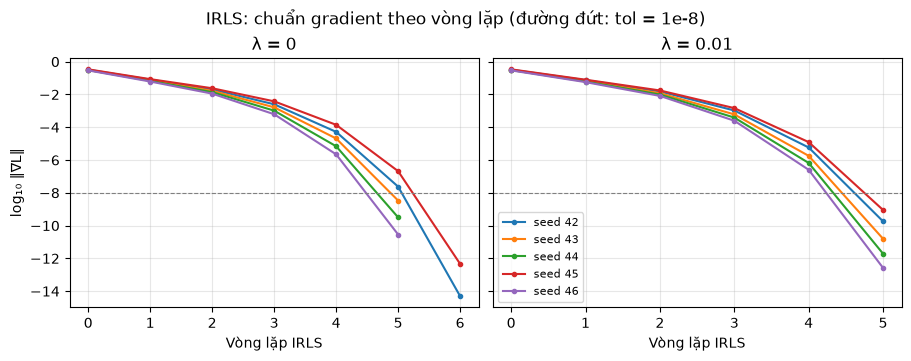

log10 ‖grad‖, seed 42, λ = 0: [ -0.49  -1.1   -1.69  -2.6   -4.28  -7.62 -14.3 ]


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True, layout="constrained")
for ax, lam in zip(axes, [0.0, 1e-2]):
    for seed in SEEDS:
        g = grad_hist[(lam, seed)]
        ax.plot(np.arange(len(g)), np.log10(np.maximum(g, 1e-300)), marker="o", ms=3,
                label=f"seed {seed}")
    ax.axhline(np.log10(1e-8), color="gray", ls="--", lw=0.8)
    ax.set_title(f"λ = {lam:g}")
    ax.set_xlabel("Vòng lặp IRLS")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("log₁₀ ‖∇L‖")
axes[1].legend(fontsize=8)
fig.suptitle("IRLS: chuẩn gradient theo vòng lặp (đường đứt: tol = 1e-8)")
save_fig(fig, "A2_irls_hoi_tu.png")
plt.show()

# Hội tụ bậc hai: log ‖g_{k+1}‖ ≈ 2·log ‖g_k‖ + hằng số ở các vòng cuối
g = grad_hist[(0.0, 42)]
print("log10 ‖grad‖, seed 42, λ = 0:", np.round(np.log10(g), 2))

## E2. GD-Armijo so với L-BFGS (softmax, K = 3)

- **dense**: n = 1000, d = 50, X ~ N(0, 1).
- **csr**: n = 2000, d = 20000, mật độ 0,5%, mỗi hàng chuẩn hóa L2 (giống TF-IDF).

Cả hai bộ sinh nhãn từ một softmax ngẫu nhiên. GD-Armijo chạy với tham số mặc định
(`tol = 1e-6`, `max_iter = 2000`), L-BFGS dùng `fit_lbfgs` (gtol = 1e-8),
sklearn dùng `LogisticRegression(C = 1/(n·λ), solver="lbfgs", tol=1e-10, max_iter=10000)`.
`gd_dat_tol` = 1 nếu GD dừng vì ‖g‖ < tol (0 nếu dừng vì loss không giảm nữa hoặc hết max_iter).

In [4]:
def make_multiclass(seed, kind):
    rng = np.random.default_rng(seed)
    if kind == "dense":
        n, d = 1000, 50
        X = rng.normal(size=(n, d))
        Z = X @ (rng.normal(size=(d, K)) * (2 / np.sqrt(d)))
    else:
        n, d = 2000, 20000
        X = sp.random(n, d, density=0.005, format="csr", random_state=seed)
        norms = np.sqrt(np.asarray(X.multiply(X).sum(axis=1)).ravel())
        X = sp.csr_matrix(sp.diags(1.0 / np.maximum(norms, 1e-12)) @ X)
        Z = np.asarray(X @ (rng.normal(size=(d, K)) * 3.0))
    P = core.softmax(Z + rng.normal(size=K))
    y = (P.cumsum(axis=1) < rng.random(n)[:, None]).sum(axis=1)
    return X, np.minimum(y, K - 1)


DATA = {(kind, seed): make_multiclass(seed, kind) for kind in ["dense", "csr"] for seed in SEEDS}
LAMS_E2 = [1e-4, 1e-3, 1e-2]

rows, gd_hist = [], {}
for kind in ["dense", "csr"]:
    for lam in LAMS_E2:
        for seed in SEEDS:
            X, y = DATA[(kind, seed)]
            n = X.shape[0]
            t = time.perf_counter()
            Wg, bg, hg = sm.fit_gd_armijo(X, y, K, lam=lam)
            t_gd = time.perf_counter() - t
            t = time.perf_counter()
            Wl, bl, res = sm.fit_lbfgs(X, y, K, lam=lam)
            t_lb = time.perf_counter() - t
            t = time.perf_counter()
            sk = LogisticRegression(C=1.0 / (n * lam), solver="lbfgs", tol=1e-10,
                                    max_iter=10000).fit(X, y)
            t_sk = time.perf_counter() - t

            Pg, Pl, Ps = sm.predict_proba(X, Wg, bg), sm.predict_proba(X, Wl, bl), sk.predict_proba(X)
            loss_gd = sm.loss_grad(Wg, bg, X, y, lam)[0]
            loss_lb = sm.loss_grad(Wl, bl, X, y, lam)[0]
            rows.append(dict(
                du_lieu=kind, lam=lam, seed=seed,
                loss_gd=loss_gd, loss_lbfgs=loss_lb, chenh_loss=loss_gd - loss_lb,
                max_dp_gd_lbfgs=np.max(np.abs(Pg - Pl)),
                max_dp_gd_sklearn=np.max(np.abs(Pg - Ps)),
                max_dp_lbfgs_sklearn=np.max(np.abs(Pl - Ps)),
                vong_gd=len(hg["step"]), vong_lbfgs=res.nit, vong_sklearn=int(sk.n_iter_[0]),
                gd_dat_tol=float(hg["grad_norm"][-1] < 1e-6),
                t_gd_s=t_gd, t_lbfgs_s=t_lb, t_sklearn_s=t_sk,
            ))
            gd_hist[(kind, lam, seed)] = hg

e2 = summarize(pd.DataFrame(rows), ["du_lieu", "lam"])
save_csv(e2, "A2_gd_vs_lbfgs.csv")
e2

Đã lưu results/A2_gd_vs_lbfgs.csv: 6 dòng × 29 cột


,du_lieu,lam,so_seed,loss_gd_mean,loss_gd_std,loss_lbfgs_mean,loss_lbfgs_std,chenh_loss_mean,chenh_loss_std,max_dp_gd_lbfgs_mean,...,vong_sklearn_mean,vong_sklearn_std,gd_dat_tol_mean,gd_dat_tol_std,t_gd_s_mean,t_gd_s_std,t_lbfgs_s_mean,t_lbfgs_s_std,t_sklearn_s_mean,t_sklearn_s_std
0,dense,0.0001,5,0.509420,0.076487,0.509420,0.076487,1.923382e-10,3.676152e-10,0.000025,...,31.8,16.330952,0.4,0.547723,0.069921,0.090017,0.022192,0.005814,0.017356,0.003971
1,dense,0.0010,5,0.513808,0.075891,0.513808,0.075891,1.222995e-10,2.337249e-10,0.000018,...,29.8,13.663821,0.6,0.547723,0.054223,0.059618,0.015615,0.004658,0.012196,0.002885
2,dense,0.0100,5,0.547671,0.074246,0.547671,0.074246,2.241473e-11,3.895109e-11,0.000006,...,23.0,5.830952,0.6,0.547723,0.023595,0.017574,0.011082,0.002626,0.008085,0.001381
3,csr,0.0001,5,0.491725,0.009445,0.491557,0.009505,1.679197e-04,6.637281e-05,0.012709,...,110.8,8.555700,0.0,0.000000,4.196797,0.331880,0.707639,0.083351,0.730675,0.056804
4,csr,0.0010,5,0.933042,0.017343,0.933042,0.017343,3.789121e-09,7.005407e-10,0.000023,...,36.8,8.378544,0.0,0.000000,2.248943,0.127002,0.122133,0.061083,0.219958,0.047617
5,csr,0.0100,5,1.058611,0.019781,1.058611,0.019781,2.035468e-10,6.117136e-11,0.000004,...,14.6,3.209361,0.0,0.000000,0.242472,0.013523,0.043054,0.008250,0.081476,0.020327


Đã lưu results/A2_hoi_tu_softmax.png


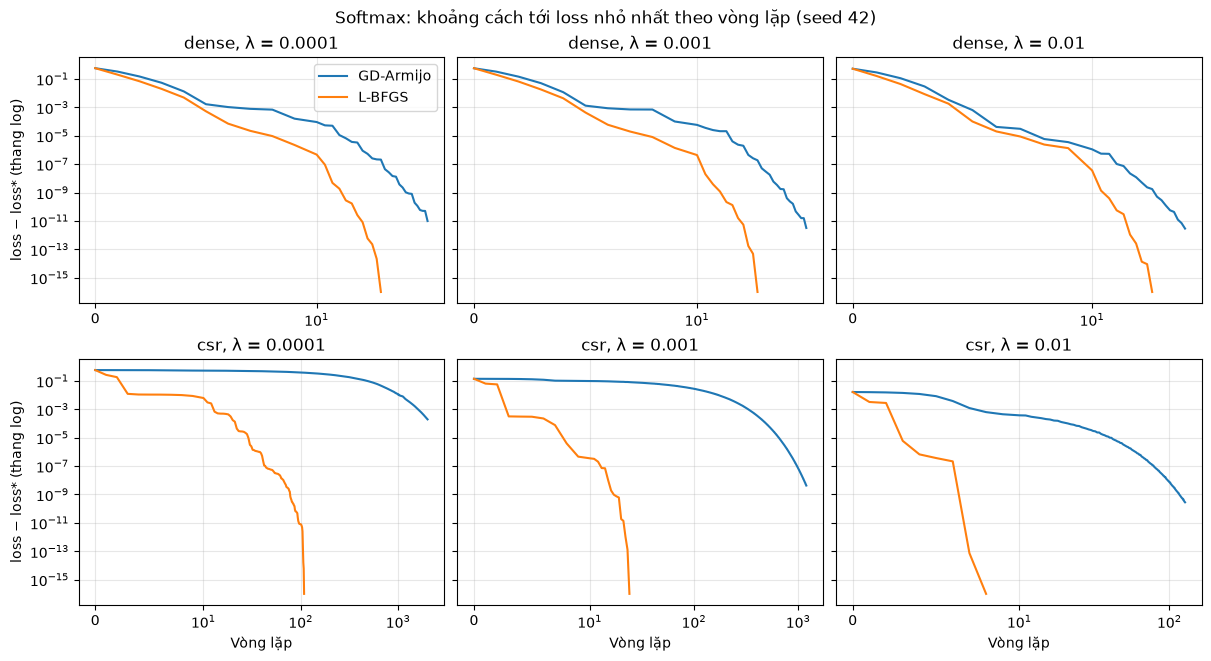

In [5]:
def lbfgs_trace(X, y, lam):
    # Chạy lại L-BFGS-B như fit_lbfgs nhưng ghi loss ở mỗi vòng qua callback.
    n, d = X.shape
    W0, b0 = sm._init_params(y, K, d, np.full(n, 1.0 / n))

    def fun(theta):
        W, b = theta[: d * K].reshape(d, K), theta[d * K:]
        f, dW, db = sm.loss_grad(W, b, X, y, lam)
        return f, np.r_[dW.ravel(), db]

    x0 = np.r_[W0.ravel(), b0]
    trace = [fun(x0)[0]]

    def callback(intermediate_result):          # scipy truyền OptimizeResult có .fun
        trace.append(intermediate_result.fun)

    minimize(fun, x0, method="L-BFGS-B", jac=True, callback=callback,
             options={"maxiter": 1000, "gtol": 1e-8, "ftol": 1e-15})
    return np.asarray(trace)


fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharey="row", layout="constrained")
for i, kind in enumerate(["dense", "csr"]):
    X, y = DATA[(kind, 42)]
    for j, lam in enumerate(LAMS_E2):
        ax = axes[i, j]
        f_gd = np.asarray(gd_hist[(kind, lam, 42)]["loss"])
        f_lb = lbfgs_trace(X, y, lam)
        f_star = min(f_gd.min(), f_lb.min())
        ax.semilogy(np.maximum(f_gd - f_star, 1e-16), label="GD-Armijo")
        ax.semilogy(np.maximum(f_lb - f_star, 1e-16), label="L-BFGS")
        ax.set_title(f"{kind}, λ = {lam:g}")
        ax.set_xscale("symlog", linthresh=10)
        ax.grid(alpha=0.3, which="both")
        if i == 1:
            ax.set_xlabel("Vòng lặp")
        if j == 0:
            ax.set_ylabel("loss − loss* (thang log)")
axes[0, 0].legend()
fig.suptitle("Softmax: khoảng cách tới loss nhỏ nhất theo vòng lặp (seed 42)")
save_fig(fig, "A2_hoi_tu_softmax.png")
plt.show()

## E3. Ổn định số

Logit Z ~ N(0, 1) cỡ (1000, 3) nhân với hệ số ∈ {1, 10, 100, 1000}. So sánh cách tính
**ngây thơ** (gọi `np.exp` trực tiếp trên logit — chỉ được phép trong notebook này để minh họa)
với `core.softmax`, `core.sigmoid` (trên cột đầu của Z), và log-loss `core.logsumexp(Z) − Z[y]`.
Tham chiếu: `scipy.special.softmax`, `expit`, `logsumexp`.
`sai_so_max` là sai số tuyệt đối lớn nhất, chỉ tính trên các giá trị hữu hạn
(giá trị nan/inf được đếm riêng ở `so_nan`, `so_inf`).

In [6]:
def naive_softmax(Z):
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)


def naive_sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def naive_logloss(Z, y):
    return -np.log(naive_softmax(Z)[np.arange(len(y)), y])


rows = []
for scale in [1, 10, 100, 1000]:
    for seed in SEEDS:
        rng = np.random.default_rng(seed)
        Z = rng.normal(size=(1000, K)) * scale
        y = rng.integers(0, K, size=1000)
        z, r = Z[:, 0], np.arange(1000)
        ref = {"softmax": sp_softmax(Z, axis=1), "sigmoid": expit(z),
               "log_loss": sp_logsumexp(Z, axis=1) - Z[r, y]}
        with np.errstate(all="ignore"):
            cands = {
                ("softmax", "ngay_tho"): naive_softmax(Z),
                ("softmax", "core"): core.softmax(Z),
                ("sigmoid", "ngay_tho"): naive_sigmoid(z),
                ("sigmoid", "core"): core.sigmoid(z),
                ("log_loss", "ngay_tho"): naive_logloss(Z, y),
                ("log_loss", "core"): core.logsumexp(Z) - Z[r, y],
            }
        for (ham, cach), v in cands.items():
            ok = np.isfinite(v)
            rows.append(dict(
                ham=ham, cach=cach, he_so=scale, seed=seed,
                so_nan=int(np.isnan(v).sum()), so_inf=int(np.isinf(v).sum()),
                sai_so_max=np.max(np.abs(v[ok] - ref[ham][ok])) if ok.any() else np.nan,
            ))

e3 = summarize(pd.DataFrame(rows), ["ham", "cach", "he_so"])
save_csv(e3, "A2_on_dinh_so.csv")
e3

Đã lưu results/A2_on_dinh_so.csv: 24 dòng × 10 cột


,ham,cach,he_so,so_seed,so_nan_mean,so_nan_std,so_inf_mean,so_inf_std,sai_so_max_mean,sai_so_max_std
0,softmax,ngay_tho,1,5,0.0,0.000000,0.0,0.000000,2.442491e-16,4.965068e-17
1,softmax,core,1,5,0.0,0.000000,0.0,0.000000,2.220446e-16,0.000000e+00
2,sigmoid,ngay_tho,1,5,0.0,0.000000,0.0,0.000000,0.000000e+00,0.000000e+00
3,sigmoid,core,1,5,0.0,0.000000,0.0,0.000000,1.221245e-16,2.482534e-17
4,log_loss,ngay_tho,1,5,0.0,0.000000,0.0,0.000000,7.993606e-16,1.986027e-16
5,log_loss,core,1,5,0.0,0.000000,0.0,0.000000,6.217249e-16,2.432377e-16
6,softmax,ngay_tho,10,5,0.0,0.000000,0.0,0.000000,3.330669e-16,0.000000e+00
7,softmax,core,10,5,0.0,0.000000,0.0,0.000000,2.686740e-15,8.396692e-16
8,sigmoid,ngay_tho,10,5,0.0,0.000000,0.0,0.000000,0.000000e+00,0.000000e+00
9,sigmoid,core,10,5,0.0,0.000000,0.0,0.000000,1.998401e-16,4.965068e-17


## E4. Ảnh hưởng của λ (softmax, bộ CSR của E2)

GD-Armijo với tham số mặc định (`tol = 1e-6`, `max_iter = 2000`).

In [7]:
LAMS_E4 = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
rows = []
for lam in LAMS_E4:
    for seed in SEEDS:
        X, y = DATA[("csr", seed)]
        t = time.perf_counter()
        W, b, h = sm.fit_gd_armijo(X, y, K, lam=lam)
        rows.append(dict(
            lam=lam, seed=seed,
            vong_gd=len(h["step"]), t_gd_s=time.perf_counter() - t,
            norm_W_F=np.linalg.norm(W), loss_train=h["loss"][-1],
            gd_dat_tol=float(h["grad_norm"][-1] < 1e-6),
        ))

e4 = summarize(pd.DataFrame(rows), ["lam"])
save_csv(e4, "A2_lambda.csv")
e4

Đã lưu results/A2_lambda.csv: 5 dòng × 12 cột


,lam,so_seed,vong_gd_mean,vong_gd_std,t_gd_s_mean,t_gd_s_std,norm_W_F_mean,norm_W_F_std,loss_train_mean,loss_train_std,gd_dat_tol_mean,gd_dat_tol_std
0,0.00001,5,2000.0,0.000000,3.904702,0.136260,116.017388,3.923807,0.145621,0.001383,0.0,0.0
1,0.00010,5,2000.0,0.000000,3.968281,0.054432,64.539912,0.825793,0.491725,0.009445,0.0,0.0
2,0.00100,5,1181.2,74.287953,2.288458,0.150886,15.411292,0.150899,0.933042,0.017343,0.0,0.0
3,0.01000,5,128.0,7.176350,0.246172,0.014458,1.808627,0.018383,1.058611,0.019781,0.0,0.0
4,0.10000,5,18.8,1.923538,0.039089,0.003316,0.183999,0.001858,1.073590,0.020070,1.0,0.0


Đã lưu results/A2_lambda.png


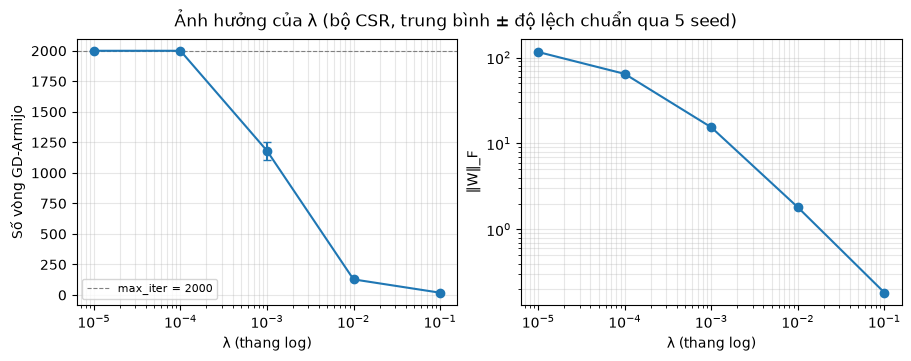

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")
for ax, m, label in [(axes[0], "vong_gd", "Số vòng GD-Armijo"),
                     (axes[1], "norm_W_F", "‖W‖_F")]:
    ax.errorbar(e4["lam"], e4[f"{m}_mean"], yerr=e4[f"{m}_std"], marker="o", capsize=3)
    ax.set_xscale("log")
    ax.set_xlabel("λ (thang log)")
    ax.set_ylabel(label)
    ax.grid(alpha=0.3, which="both")
axes[0].axhline(2000, color="gray", ls="--", lw=0.8, label="max_iter = 2000")
axes[0].legend(fontsize=8)
axes[1].set_yscale("log")
fig.suptitle("Ảnh hưởng của λ (bộ CSR, trung bình ± độ lệch chuẩn qua 5 seed)")
save_fig(fig, "A2_lambda.png")
plt.show()

## E5. Thống kê tìm bước Armijo (từ history của E2)

Mỗi vòng thử bước `t = 2·t_trước` (vòng đầu `t = t0 = 1`) rồi nhân `beta = 0,5` tới khi thỏa Armijo.
`ti_le_khong_lui` = tỷ lệ vòng chấp nhận ngay bước thử đầu tiên.

In [9]:
rows = []
for (kind, lam, seed), h in gd_hist.items():
    t_acc = np.asarray(h["step"])
    nb = np.asarray(h["n_backtrack"])
    rows.append(dict(
        du_lieu=kind, lam=lam, seed=seed, vong=len(t_acc),
        lui_buoc_tb=nb.mean(), lui_buoc_max=nb.max(), ti_le_khong_lui=(nb == 0).mean(),
        t_min=t_acc.min(), t_p25=np.quantile(t_acc, 0.25), t_trung_vi=np.median(t_acc),
        t_p75=np.quantile(t_acc, 0.75), t_max=t_acc.max(),
    ))

e5 = summarize(pd.DataFrame(rows), ["du_lieu", "lam"])
save_csv(e5, "A2_armijo.csv")
e5

Đã lưu results/A2_armijo.csv: 6 dòng × 21 cột


,du_lieu,lam,so_seed,vong_mean,vong_std,lui_buoc_tb_mean,lui_buoc_tb_std,lui_buoc_max_mean,lui_buoc_max_std,ti_le_khong_lui_mean,...,t_min_mean,t_min_std,t_p25_mean,t_p25_std,t_trung_vi_mean,t_trung_vi_std,t_p75_mean,t_p75_std,t_max_mean,t_max_std
0,dense,0.0001,5,172.4,226.122312,0.949076,0.037205,2.4,0.547723,0.448042,...,1.0,0.0,4.0,0.0,7.2,1.788854,8.0,0.0,16.0,0.000000
1,dense,0.0010,5,137.8,161.594245,0.949081,0.037555,2.6,0.547723,0.467625,...,1.0,0.0,4.0,0.0,7.2,1.788854,8.0,0.0,16.0,0.000000
2,dense,0.0100,5,67.2,52.251316,0.930996,0.040042,2.6,0.547723,0.441697,...,1.0,0.0,4.0,0.0,4.8,1.788854,8.0,0.0,12.8,4.381780
3,csr,0.0001,5,2000.0,0.000000,0.998000,0.000000,5.0,1.000000,0.233500,...,1.0,0.0,8.0,0.0,8.0,0.000000,8.0,0.0,89.6,35.054244
4,csr,0.0010,5,1181.2,74.287953,0.996927,0.000608,5.2,0.836660,0.427134,...,1.0,0.0,4.0,0.0,6.4,2.190890,8.0,0.0,89.6,35.054244
5,csr,0.0100,5,128.0,7.176350,0.973414,0.004146,4.6,0.547723,0.434641,...,1.0,0.0,4.0,0.0,5.6,2.190890,8.0,0.0,64.0,0.000000


## Tóm tắt (mean ± std qua 5 seed) — dán vào báo cáo

In [10]:
def fmt(m, s):
    if pd.isna(m):
        return "—"
    s_txt = "0" if pd.isna(s) or s == 0 else f"{s:.2g}"
    return f"{m:.3g} ± {s_txt}"


def md_table(df, keys):
    metrics = [c[: -len("_mean")] for c in df.columns if c.endswith("_mean")]
    out = df[keys].copy()
    for m in metrics:
        out[m] = [fmt(a, s) for a, s in zip(df[f"{m}_mean"], df[f"{m}_std"])]
    return out.to_markdown(index=False)


for title, name, keys in [
    ("E1. IRLS so với sklearn", "A2_irls_vs_sklearn.csv", ["lam"]),
    ("E2. GD-Armijo so với L-BFGS", "A2_gd_vs_lbfgs.csv", ["du_lieu", "lam"]),
    ("E3. Ổn định số", "A2_on_dinh_so.csv", ["ham", "cach", "he_so"]),
    ("E4. Ảnh hưởng của λ", "A2_lambda.csv", ["lam"]),
    ("E5. Tìm bước Armijo", "A2_armijo.csv", ["du_lieu", "lam"]),
]:
    print(f"### {title} (`results/{name}`)\n")
    print(md_table(pd.read_csv(RESULTS / name), keys))
    print()

print(f"Tổng thời gian chạy notebook: {time.perf_counter() - T_START:.1f} s")

### E1. IRLS so với sklearn (`results/A2_irls_vs_sklearn.csv`)

|   lam | max_abs_dw         | abs_db             | chenh_loss          | vong_irls   | n_iter_sklearn   | t_irls_s           | t_sklearn_s       |
|------:|:-------------------|:-------------------|:--------------------|:------------|:-----------------|:-------------------|:------------------|
|  0    | 1.6e-08 ± 1.5e-08  | 6.09e-09 ± 4.3e-09 | -4.44e-17 ± 1.1e-16 | 5.4 ± 0.55  | 11.6 ± 0.55      | 0.000894 ± 0.00043 | 0.00405 ± 0.0043  |
|  0.01 | 1.06e-08 ± 6.9e-09 | 4e-09 ± 1.7e-09    | -4.44e-17 ± 4.6e-17 | 5 ± 0       | 10.8 ± 0.84      | 0.000659 ± 1.4e-05 | 0.00187 ± 0.00034 |

### E2. GD-Armijo so với L-BFGS (`results/A2_gd_vs_lbfgs.csv`)

| du_lieu   |    lam | loss_gd        | loss_lbfgs     | chenh_loss         | max_dp_gd_lbfgs    | max_dp_gd_sklearn   | max_dp_lbfgs_sklearn   | vong_gd       | vong_lbfgs   | vong_sklearn   | gd_dat_tol   | t_gd_s         | t_lbfgs_s       | t_sklearn_s      |
|:----------|---